In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [50]:
data = pd.read_csv("../data/processed/daily_consumption.csv")

data["Date"] = pd.to_datetime(data["Date"])

data = data.sort_values("Date").reset_index(drop=True)

data.head()

,Date,Daily_Consumption_kWh
0,2006-12-17,56.507667
1,2006-12-18,36.730433
2,2006-12-19,27.769900
3,2006-12-20,37.095800
4,2006-12-21,28.610400


In [51]:
data = data.set_index("Date")

full_dates = pd.date_range(
    start=data.index.min(),
    end=data.index.max(),
    freq="D"
)

data = data.reindex(full_dates)

data.index.name = "Date"

data = data.reset_index()

In [52]:
target = "Daily_Consumption_kWh"

In [53]:
data["Year"] = data["Date"].dt.year

data["Month"] = data["Date"].dt.month

data["Day"] = data["Date"].dt.day

data["Day_of_Week"] = data["Date"].dt.dayofweek

data["Is_Weekend"] = (
    data["Day_of_Week"].isin([5, 6]).astype(int)
)

data["Month_Sin"] = np.sin(
    2 * np.pi * data["Month"] / 12
)

data["Month_Cos"] = np.cos(
    2 * np.pi * data["Month"] / 12
)

In [54]:
data["Consumption_Lag_1"] = data[target].shift(1)

data["Consumption_Lag_7"] = data[target].shift(7)

data["Consumption_Lag_30"] = data[target].shift(30)

In [55]:
data["Rolling_Mean_7"] = (
    data[target].shift(1).rolling(7).mean()
)

data["Rolling_Mean_30"] = (
    data[target].shift(1).rolling(30).mean()
)

In [56]:
features = [
    "Year",
    "Month",
    "Day",
    "Day_of_Week",
    "Is_Weekend",
    "Consumption_Lag_1",
    "Consumption_Lag_7",
    "Consumption_Lag_30",
    "Rolling_Mean_7",
    "Rolling_Mean_30",
    "Month_Sin",
    "Month_Cos"
]

model_data = data.dropna(
    subset=features + [target]
).copy()

model_data = model_data.reset_index(drop=True)

In [57]:
print("Original records:", len(data))

print("Records available for modelling:", len(model_data))

print("Missing values:")
print(model_data[features + [target]].isnull().sum())

Original records: 1440
Records available for modelling: 990
Missing values:
Year                     0
Month                    0
Day                      0
Day_of_Week              0
Is_Weekend               0
Consumption_Lag_1        0
Consumption_Lag_7        0
Consumption_Lag_30       0
Rolling_Mean_7           0
Rolling_Mean_30          0
Month_Sin                0
Month_Cos                0
Daily_Consumption_kWh    0
dtype: int64


In [58]:
X = model_data[features]

y = model_data[target]

In [59]:
print("X shape:", X.shape)

print("y shape:", y.shape)

X shape: (990, 12)
y shape: (990,)


In [60]:
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]

X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]

y_test = y.iloc[split_index:]

In [61]:
print("Training records:", len(X_train))

print("Testing records:", len(X_test))

print("Training period:",
      model_data["Date"].iloc[0],
      "to",
      model_data["Date"].iloc[split_index - 1])

print("Testing period:",
      model_data["Date"].iloc[split_index],
      "to",
      model_data["Date"].iloc[-1])

Training records: 792
Testing records: 198
Training period: 2007-01-16 00:00:00 to 2009-12-27 00:00:00
Testing period: 2009-12-28 00:00:00 to 2010-11-25 00:00:00


In [62]:
baseline_predictions = X_test["Consumption_Lag_1"]

In [63]:
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Baseline MAE:", baseline_mae)

print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 4.798884511784512
Baseline RMSE: 6.749796242811519


In [64]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[-0.1 , 0.16,-0.03,...,-0.06, 2.14, 2.61]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['Year','Month','Day',...,'Rolling_Mean_30','Month_Sin','Month_Cos']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,205.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [65]:
lr_predictions = lr_model.predict(X_test)

In [66]:
lr_mae = mean_absolute_error(
    y_test,
    lr_predictions
)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, lr_predictions)
)

lr_r2 = r2_score(
    y_test,
    lr_predictions
)

print("Linear Regression Results")

print("MAE:", lr_mae)

print("RMSE:", lr_rmse)

print("R2 Score:", lr_r2)

Linear Regression Results
MAE: 4.174634862723273
RMSE: 5.670469294014161
R2 Score: 0.5015762635518507


In [67]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [68]:
rf_predictions = rf_model.predict(X_test)

In [69]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest Results")

print("MAE:", rf_mae)

print("RMSE:", rf_rmse)

print("R2 Score:", rf_r2)

Random Forest Results
MAE: 4.0024738444288
RMSE: 5.2412836208491775
R2 Score: 0.5741702172164156


In [70]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [71]:
from xgboost import XGBRegressor

In [72]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    objective="reg:squarederror"
)

xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [73]:
xgb_predictions = xgb_model.predict(X_test)

In [74]:
xgb_mae = mean_absolute_error(
    y_test,
    xgb_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_predictions)
)

xgb_r2 = r2_score(
    y_test,
    xgb_predictions
)

print("XGBoost Results")

print("MAE:", xgb_mae)

print("RMSE:", xgb_rmse)

print("R2 Score:", xgb_r2)

XGBoost Results
MAE: 4.059153121939251
RMSE: 5.573264082587134
R2 Score: 0.5185181122265936


In [75]:
results = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],

    "MAE": [
        baseline_mae,
        lr_mae,
        rf_mae,
        xgb_mae
    ],

    "RMSE": [
        baseline_rmse,
        lr_rmse,
        rf_rmse,
        xgb_rmse
    ],

    "R2 Score": [
        r2_score(y_test, baseline_predictions),
        lr_r2,
        rf_r2,
        xgb_r2
    ]
})

results = results.sort_values("MAE")

results

,Model,MAE,RMSE,R2 Score
2,Random Forest,4.002474,5.241284,0.574170
3,XGBoost,4.059153,5.573264,0.518518
1,Linear Regression,4.174635,5.670469,0.501576
0,Naive Baseline,4.798885,6.749796,0.293777


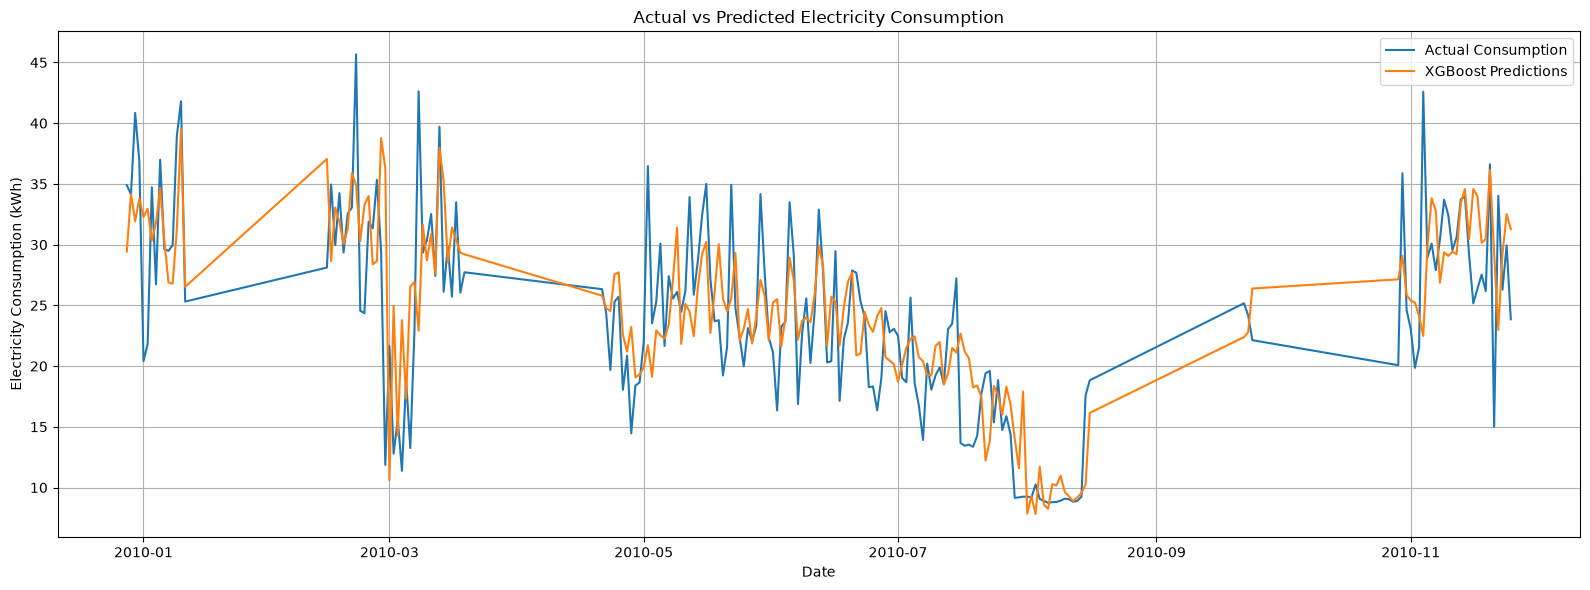

In [76]:
plt.figure(figsize=(16, 6))

plt.plot(
    model_data["Date"].iloc[split_index:],
    y_test.values,
    label="Actual Consumption"
)

plt.plot(
    model_data["Date"].iloc[split_index:],
    xgb_predictions,
    label="XGBoost Predictions"
)

plt.title("Actual vs Predicted Electricity Consumption")

plt.xlabel("Date")

plt.ylabel("Electricity Consumption (kWh)")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

In [77]:
model_predictions = {
    "Linear Regression": (lr_model, lr_predictions),
    "Random Forest": (rf_model, rf_predictions),
    "XGBoost": (xgb_model, xgb_predictions)
}

best_model_name = results[
    results["Model"] != "Naive Baseline"
].iloc[0]["Model"]

best_model, best_predictions = model_predictions[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [78]:
joblib.dump(
    best_model,
    "../models/best_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [79]:
joblib.dump(
    features,
    "../models/model_features.pkl"
)

['../models/model_features.pkl']

In [80]:
evaluation = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": best_predictions
})

evaluation["Error"] = (
    evaluation["Actual"] - evaluation["Predicted"]
)

evaluation["Absolute_Error"] = (
    evaluation["Error"].abs()
)

evaluation.head(10)

,Actual,Predicted,Error,Absolute_Error
0,34.901633,33.180974,1.720660,1.720660
1,34.132800,31.941657,2.191143,2.191143
2,40.851833,29.653827,11.198006,11.198006
3,36.864867,37.426848,-0.561981,0.561981
4,20.404200,31.723367,-11.319167,11.319167
5,21.813933,34.189029,-12.375095,12.375095
6,34.724233,33.556066,1.168167,1.168167
7,26.735533,31.876397,-5.140864,5.140864
8,36.996333,32.756263,4.240070,4.240070
9,29.619667,31.569898,-1.950232,1.950232


In [81]:
mae = mean_absolute_error(
    y_test,
    best_predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test, best_predictions)
)

r2 = r2_score(
    y_test,
    best_predictions
)

print("Selected Model:", best_model_name)

print("Mean Absolute Error:", mae)

print("Root Mean Squared Error:", rmse)

print("R2 Score:", r2)

Selected Model: Random Forest
Mean Absolute Error: 4.0024738444288
Root Mean Squared Error: 5.2412836208491775
R2 Score: 0.5741702172164156


In [82]:
wape = (
    evaluation["Absolute_Error"].sum()
    / evaluation["Actual"].sum()
) * 100

print("WAPE:", round(wape, 2), "%")

WAPE: 16.78 %


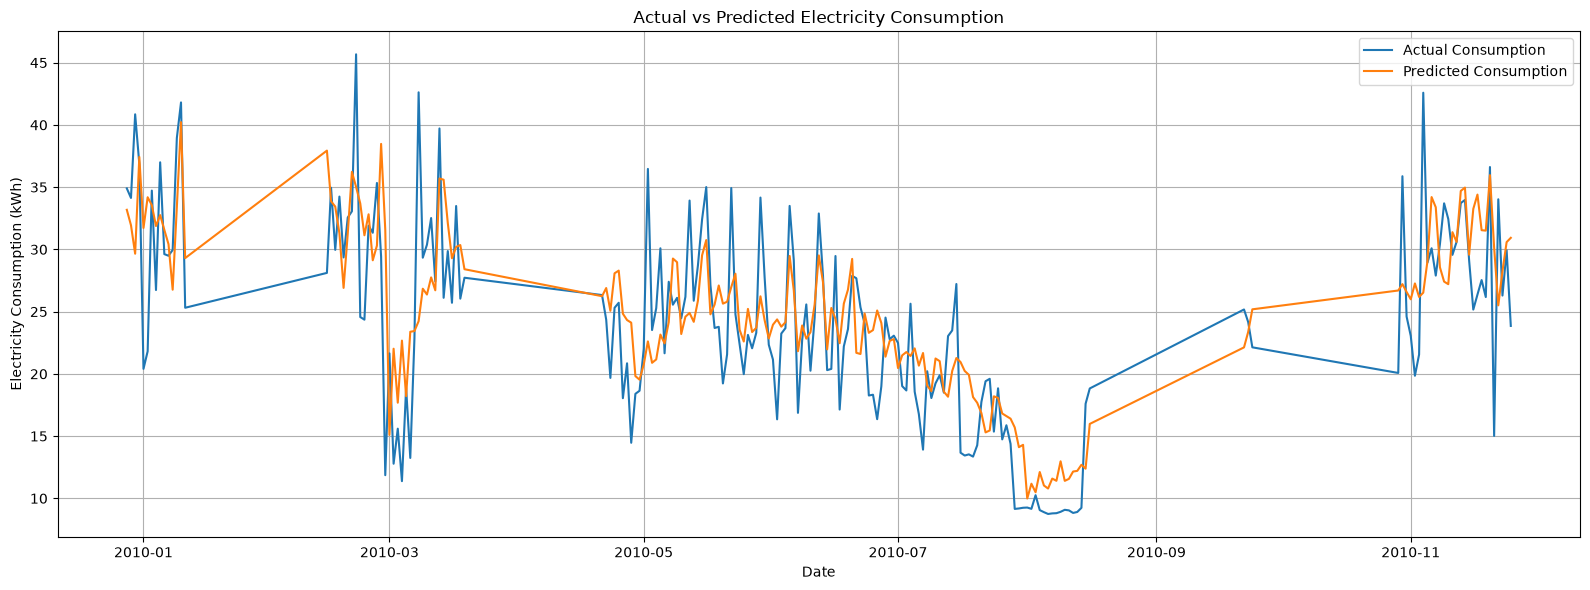

In [83]:
plt.figure(figsize=(16, 6))

plt.plot(
    model_data["Date"].iloc[-len(y_test):],
    y_test.values,
    label="Actual Consumption"
)

plt.plot(
    model_data["Date"].iloc[-len(y_test):],
    best_predictions,
    label="Predicted Consumption"
)

plt.title("Actual vs Predicted Electricity Consumption")

plt.xlabel("Date")

plt.ylabel("Electricity Consumption (kWh)")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

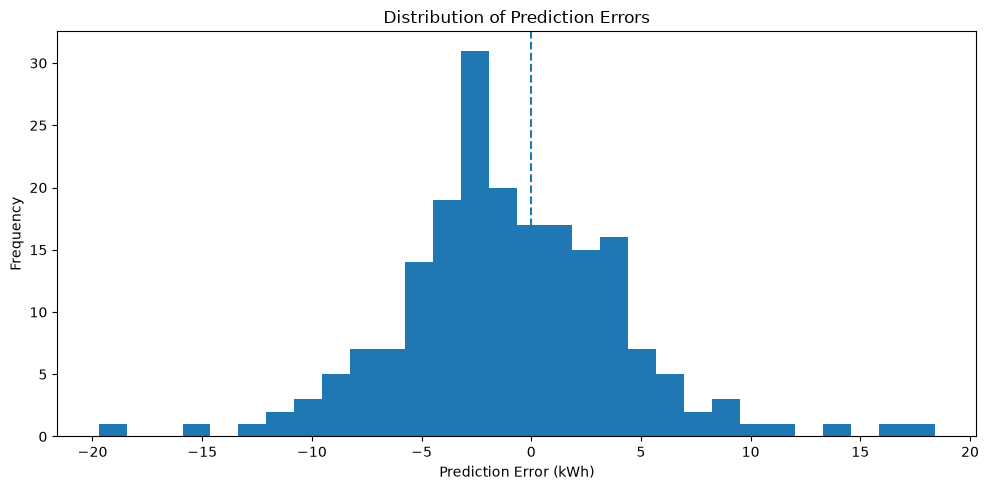

In [84]:
plt.figure(figsize=(10, 5))

plt.hist(
    evaluation["Error"],
    bins=30
)

plt.title("Distribution of Prediction Errors")

plt.xlabel("Prediction Error (kWh)")

plt.ylabel("Frequency")

plt.axvline(
    0,
    linestyle="--"
)

plt.tight_layout()

plt.show()

In [85]:
evaluation["Date"] = model_data["Date"].iloc[-len(y_test):].values

worst_predictions = evaluation.sort_values(
    "Absolute_Error",
    ascending=False
)

worst_predictions.head(10)

,Actual,Predicted,Error,Absolute_Error,Date
29,11.861100,31.567116,-19.706016,19.706016,2010-02-28
37,42.618300,24.233998,18.384302,18.384302,2010-03-08
176,42.585767,26.524038,16.061729,16.061729,2010-11-04
193,15.015167,30.154659,-15.139493,15.139493,2010-11-21
60,36.465167,22.611497,13.853669,13.853669,2010-05-02
5,21.813933,34.189029,-12.375095,12.375095,2010-01-02
4,20.404200,31.723367,-11.319167,11.319167,2010-01-01
33,11.381333,22.672103,-11.290770,11.290770,2010-03-04
2,40.851833,29.653827,11.198006,11.198006,2009-12-30
22,45.671900,35.019710,10.652190,10.652190,2010-02-21


In [86]:
evaluation["Month"] = pd.to_datetime(
    evaluation["Date"]
).dt.month_name()

In [87]:
monthly_errors = evaluation.groupby(
    "Month"
)["Absolute_Error"].mean()

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

monthly_errors = monthly_errors.reindex(month_order)

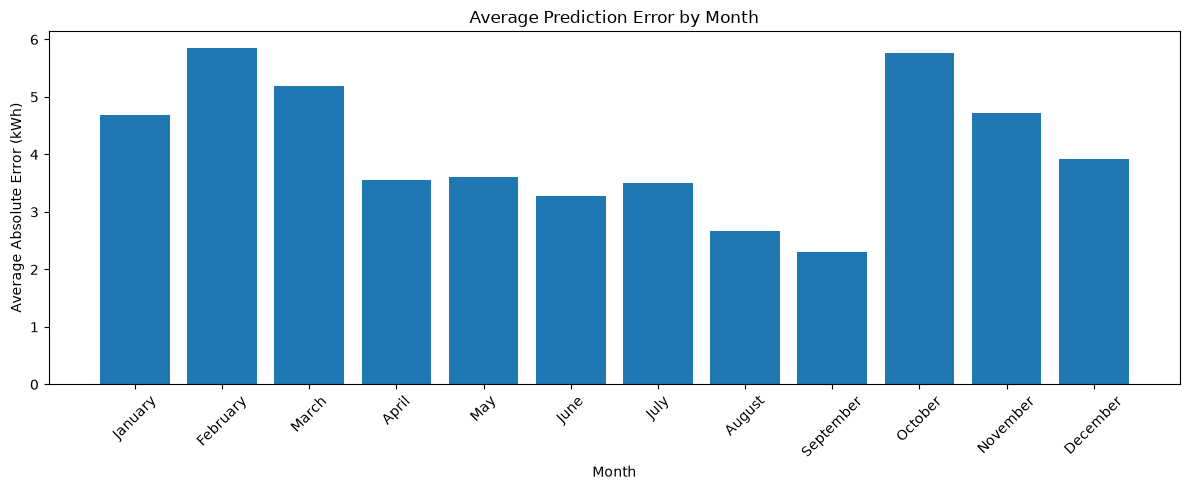

In [88]:
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_errors.index,
    monthly_errors.values
)

plt.title("Average Prediction Error by Month")

plt.xlabel("Month")

plt.ylabel("Average Absolute Error (kWh)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [89]:
from sklearn.model_selection import TimeSeriesSplit

In [90]:
tscv = TimeSeriesSplit(n_splits=5)

In [91]:
cv_mae = []

for train_index, test_index in tscv.split(X):

    X_train_cv = X.iloc[train_index]
    X_test_cv = X.iloc[test_index]

    y_train_cv = y.iloc[train_index]
    y_test_cv = y.iloc[test_index]

    model = best_model.__class__(
        **best_model.get_params()
    )

    model.fit(X_train_cv, y_train_cv)

    predictions = model.predict(X_test_cv)

    fold_mae = mean_absolute_error(
        y_test_cv,
        predictions
    )

    cv_mae.append(fold_mae)

    print("Fold MAE:", fold_mae)

Fold MAE: 6.545993705300228
Fold MAE: 6.18905633718944
Fold MAE: 4.376021363893066
Fold MAE: 4.409549639720248
Fold MAE: 3.746465043555113


In [92]:
print("Average Cross-Validation MAE:", np.mean(cv_mae))

print("MAE Standard Deviation:", np.std(cv_mae))

Average Cross-Validation MAE: 5.053417217931619
MAE Standard Deviation: 1.1044469536634316


In [93]:
evaluation.to_csv(
    "../data/processed/model_evaluation.csv",
    index=False
)

print("Model evaluation results saved successfully!")

Model evaluation results saved successfully!


In [96]:
if best_model_name in ["Random Forest", "XGBoost"]:

    importance = pd.DataFrame({
        "Feature": features,
        "Importance": best_model.feature_importances_
    })

    importance.to_csv(
        "../data/processed/feature_importance.csv",
        index=False
    )

    print("Feature importance saved successfully!")

else:
    print("Feature importance using tree-based models is not applicable.")

Feature importance saved successfully!
